# Steam Games - Exploratory Data Analysis (EDA)

**Dataset:** Steam Store Games  
**Date:** October 2026

In this notebook, we will explore the Steam games dataset to understand:
- What types of games are on Steam?
- How are prices distributed?
- Which genres and platforms are most popular?
- What do ratings look like?
- How has the number of releases changed over time?

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Plot settings
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load the Data

In [2]:
# Load the main dataset
df = pd.read_csv('steam.csv')

print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset shape: 27075 rows x 18 columns


In [3]:
# First look at the data
df.head()

,appid,name,release_date,english,developer,publisher,platforms,required_age,categories,genres,steamspy_tags,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,owners,price
0,10,Counter-Strike,2000-11-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,124534,3339,17612,317,10000000-20000000,7.19
1,20,Team Fortress Classic,1999-04-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,3318,633,277,62,5000000-10000000,3.99
2,30,Day of Defeat,2003-05-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Valve Anti-Cheat enabled,Action,FPS;World War II;Multiplayer,0,3416,398,187,34,5000000-10000000,3.99
3,40,Deathmatch Classic,2001-06-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,1273,267,258,184,5000000-10000000,3.99
4,50,Half-Life: Opposing Force,1999-11-01,1,Gearbox Software,Valve,windows;mac;linux,0,Single-player;Multi-player;Valve Anti-Cheat en...,Action,FPS;Action;Sci-fi,0,5250,288,624,415,5000000-10000000,3.99


In [4]:
# Check column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27075 entries, 0 to 27074
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   appid             27075 non-null  int64  
 1   name              27075 non-null  str    
 2   release_date      27075 non-null  str    
 3   english           27075 non-null  int64  
 4   developer         27074 non-null  str    
 5   publisher         27061 non-null  str    
 6   platforms         27075 non-null  str    
 7   required_age      27075 non-null  int64  
 8   categories        27075 non-null  str    
 9   genres            27075 non-null  str    
 10  steamspy_tags     27075 non-null  str    
 11  achievements      27075 non-null  int64  
 12  positive_ratings  27075 non-null  int64  
 13  negative_ratings  27075 non-null  int64  
 14  average_playtime  27075 non-null  int64  
 15  median_playtime   27075 non-null  int64  
 16  owners            27075 non-null  str    
 17  pric

In [5]:
# Summary statistics for numeric columns
df.describe().round(2)

,appid,english,required_age,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,price
count,27075.00,27075.00,27075.00,27075.00,27075.00,27075.00,27075.00,27075.00,27075.00
mean,596203.51,0.98,0.35,45.25,1000.56,211.03,149.80,146.06,6.08
std,250894.17,0.14,2.41,352.67,18988.72,4284.94,1827.04,2353.88,7.87
min,10.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,401230.00,1.00,0.00,0.00,6.00,2.00,0.00,0.00,1.69
50%,599070.00,1.00,0.00,7.00,24.00,9.00,0.00,0.00,3.99
75%,798760.00,1.00,0.00,23.00,126.00,42.00,0.00,0.00,7.19
max,1069460.00,1.00,18.00,9821.00,2644404.00,487076.00,190625.00,190625.00,421.99


## 3. Check for Missing Values

In [6]:
# Count missing values per column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    'Missing': missing,
    'Percentage': missing_pct
})

print(missing_report[missing_report['Missing'] > 0])
print(f"\nTotal missing values: {missing.sum()}")

           Missing  Percentage
developer        1        0.00
publisher       14        0.05

Total missing values: 15


In [7]:
# Fill missing values
df['developer'] = df['developer'].fillna('Unknown')
df['publisher'] = df['publisher'].fillna('Unknown')

print("Missing values filled with 'Unknown'")
print(f"Remaining missing: {df.isnull().sum().sum()}")

Missing values filled with 'Unknown'
Remaining missing: 0


## 4. Data Preparation

Before analysis, let's create some helpful columns.

In [8]:
# Convert release_date to datetime
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_year'] = df['release_date'].dt.year

# Calculate total ratings and positive percentage
df['total_ratings'] = df['positive_ratings'] + df['negative_ratings']
df['positive_pct'] = np.where(
    df['total_ratings'] > 0,
    round(df['positive_ratings'] / df['total_ratings'] * 100, 1),
    0
)

# Mark free vs paid games
df['is_free'] = df['price'] == 0

# Parse owners to get midpoint number
def get_owners_mid(x):
    parts = x.split('-')
    return (int(parts[0]) + int(parts[1])) / 2

df['owners_estimate'] = df['owners'].apply(get_owners_mid)

print("New columns created:")
print("  - release_year")
print("  - total_ratings")
print("  - positive_pct")
print("  - is_free")
print("  - owners_estimate")

New columns created:
  - release_year
  - total_ratings
  - positive_pct
  - is_free
  - owners_estimate


In [9]:
# Quick check of the new columns
df[['name', 'price', 'is_free', 'total_ratings', 'positive_pct', 'release_year']].head(10)

,name,price,is_free,total_ratings,positive_pct,release_year
0,Counter-Strike,7.19,False,127873,97.4,2000
1,Team Fortress Classic,3.99,False,3951,84.0,1999
2,Day of Defeat,3.99,False,3814,89.6,2003
3,Deathmatch Classic,3.99,False,1540,82.7,2001
4,Half-Life: Opposing Force,3.99,False,5538,94.8,1999
5,Ricochet,3.99,False,3442,80.1,2000
6,Half-Life,7.19,False,28855,96.2,1998
7,Counter-Strike: Condition Zero,7.19,False,13559,89.4,2004
8,Half-Life: Blue Shift,3.99,False,4242,90.1,2001
9,Half-Life 2,7.19,False,70321,96.6,2004


## 5. Price Analysis

Free games: 2560 (9.5%)
Paid games: 24515 (90.5%)


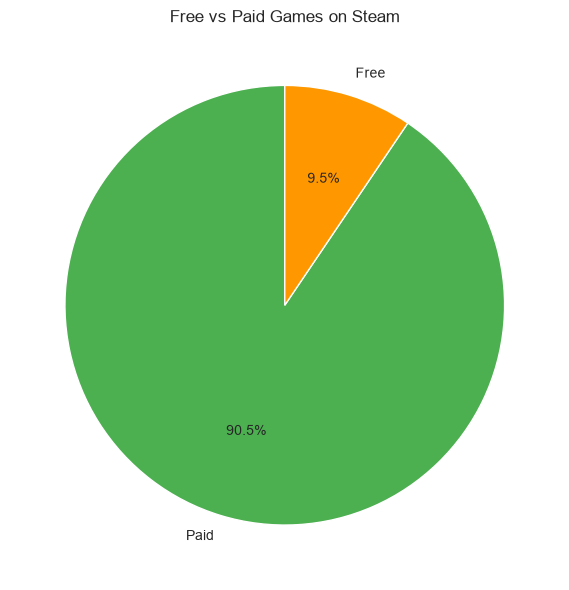

In [10]:
# How many free vs paid games?
free_count = df['is_free'].sum()
paid_count = len(df) - free_count

print(f"Free games: {free_count} ({free_count/len(df)*100:.1f}%)")
print(f"Paid games: {paid_count} ({paid_count/len(df)*100:.1f}%)")

# Pie chart
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie([paid_count, free_count],
       labels=['Paid', 'Free'],
       autopct='%1.1f%%',
       colors=['#4CAF50', '#FF9800'],
       startangle=90)
ax.set_title('Free vs Paid Games on Steam')
plt.tight_layout()
plt.savefig('01_free_vs_paid.png', dpi=150, bbox_inches='tight')
plt.show()

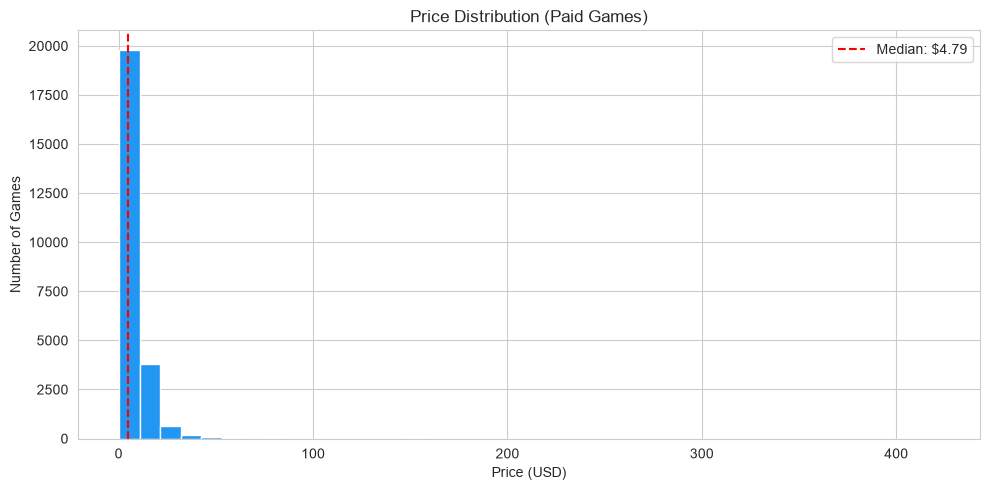

Average price: $6.71
Median price:  $4.79
Most expensive: $421.99


In [11]:
# Price distribution for paid games only
paid_games = df[df['price'] > 0]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(paid_games['price'], bins=40, color='#2196F3', edgecolor='white')
ax.set_title('Price Distribution (Paid Games)')
ax.set_xlabel('Price (USD)')
ax.set_ylabel('Number of Games')
ax.axvline(paid_games['price'].median(), color='red', linestyle='--',
           label=f"Median: ${paid_games['price'].median():.2f}")
ax.legend()
plt.tight_layout()
plt.savefig('02_price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Average price: ${paid_games['price'].mean():.2f}")
print(f"Median price:  ${paid_games['price'].median():.2f}")
print(f"Most expensive: ${paid_games['price'].max():.2f}")

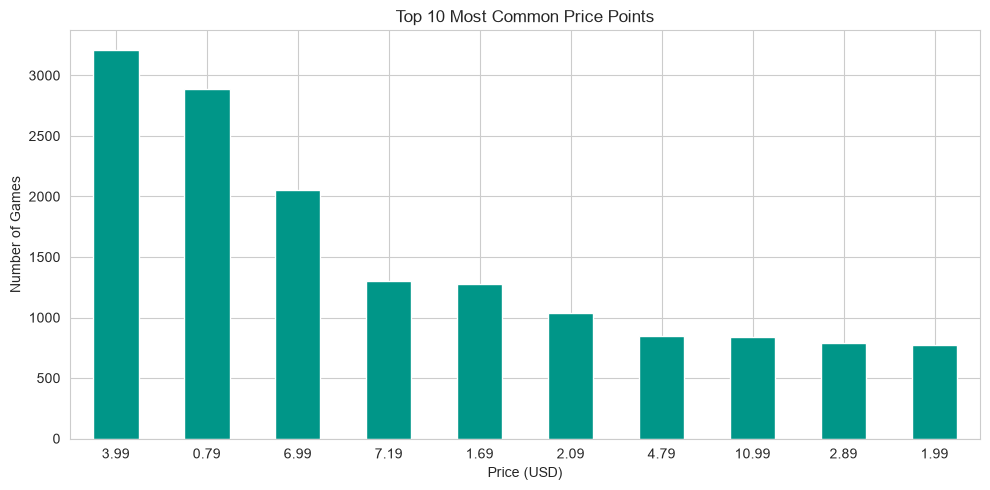

In [12]:
# Most common price points
top_prices = df[df['price'] > 0]['price'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
top_prices.plot(kind='bar', ax=ax, color='#009688', edgecolor='white')
ax.set_title('Top 10 Most Common Price Points')
ax.set_xlabel('Price (USD)')
ax.set_ylabel('Number of Games')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('03_common_prices.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Genre Analysis

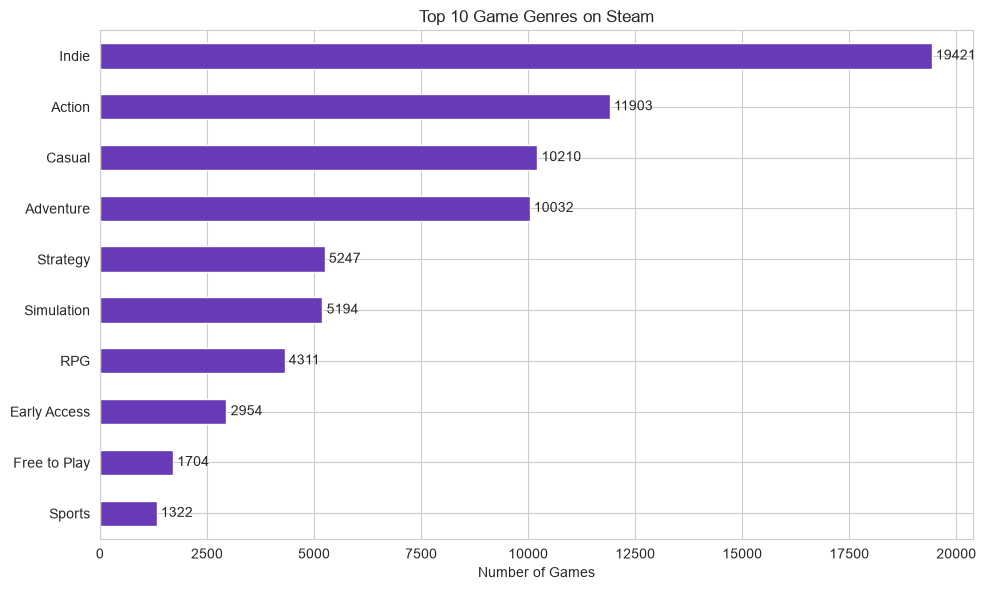

Total unique genres: 29


In [13]:
# Split genres (some games have multiple genres separated by ;)
all_genres = df['genres'].str.split(';').explode().str.strip()
genre_counts = all_genres.value_counts()

# Top 10 genres
top10 = genre_counts.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
top10.plot(kind='barh', ax=ax, color='#673AB7', edgecolor='white')
ax.set_title('Top 10 Game Genres on Steam')
ax.set_xlabel('Number of Games')
ax.set_ylabel('')
ax.invert_yaxis()

# Add count labels on bars
for i, v in enumerate(top10.values):
    ax.text(v + 100, i, str(v), va='center')

plt.tight_layout()
plt.savefig('04_top_genres.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Total unique genres: {len(genre_counts)}")

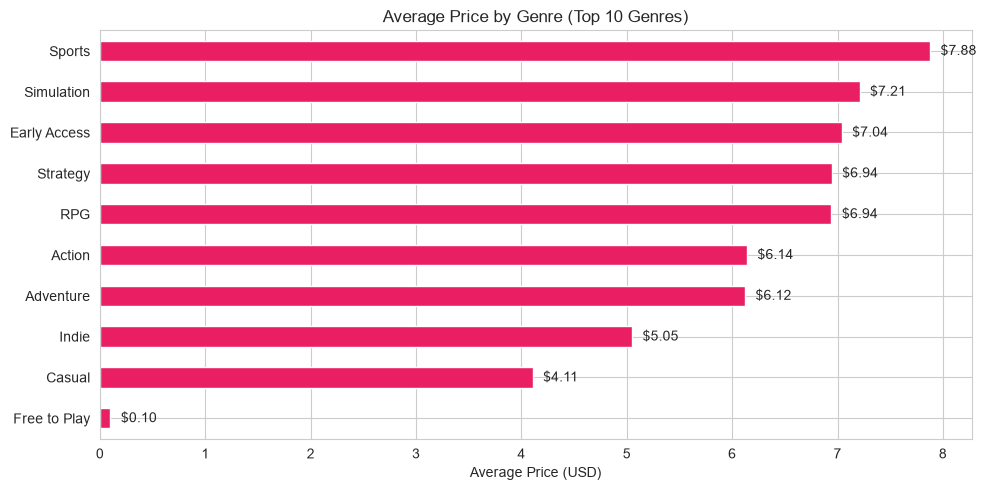

In [14]:
# Average price per genre (top 10)
genre_df = df.assign(genre=df['genres'].str.split(';')).explode('genre')
genre_df['genre'] = genre_df['genre'].str.strip()

top_genre_names = genre_counts.head(10).index.tolist()
filtered = genre_df[genre_df['genre'].isin(top_genre_names)]
avg_price = filtered.groupby('genre')['price'].mean().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
avg_price.plot(kind='barh', ax=ax, color='#E91E63', edgecolor='white')
ax.set_title('Average Price by Genre (Top 10 Genres)')
ax.set_xlabel('Average Price (USD)')
ax.set_ylabel('')

for i, v in enumerate(avg_price.values):
    ax.text(v + 0.1, i, f'${v:.2f}', va='center')

plt.tight_layout()
plt.savefig('05_genre_avg_price.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Platform Analysis

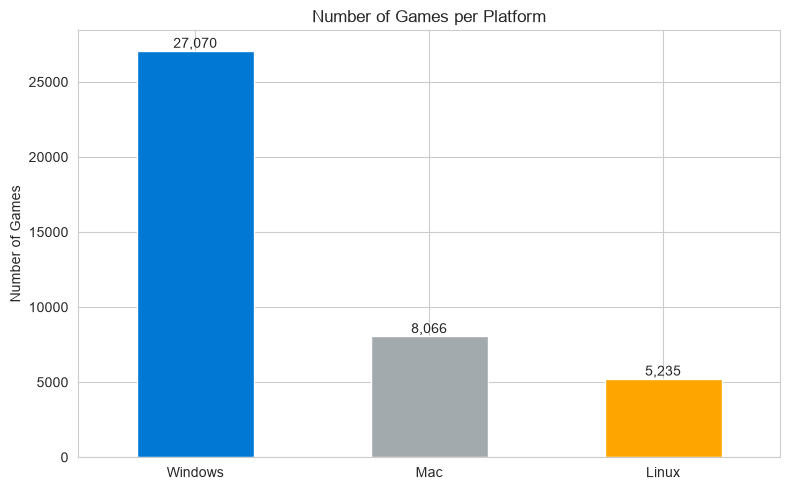

Windows: 27,070 (100.0%)
Mac:     8,066 (29.8%)
Linux:   5,235 (19.3%)


In [15]:
# Count games per platform
windows = df['platforms'].str.contains('windows').sum()
mac = df['platforms'].str.contains('mac').sum()
linux = df['platforms'].str.contains('linux').sum()

platforms = pd.Series({'Windows': windows, 'Mac': mac, 'Linux': linux})

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#0078D4', '#A2AAAD', '#FFA500']
platforms.plot(kind='bar', ax=ax, color=colors, edgecolor='white')
ax.set_title('Number of Games per Platform')
ax.set_ylabel('Number of Games')
plt.xticks(rotation=0)

# Add labels
for i, v in enumerate(platforms.values):
    ax.text(i, v + 200, f'{v:,}', ha='center')

plt.tight_layout()
plt.savefig('06_platforms.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Windows: {windows:,} ({windows/len(df)*100:.1f}%)")
print(f"Mac:     {mac:,} ({mac/len(df)*100:.1f}%)")
print(f"Linux:   {linux:,} ({linux/len(df)*100:.1f}%)")

## 8. Ratings Analysis

Games with 10+ ratings: 20,511 out of 27,075


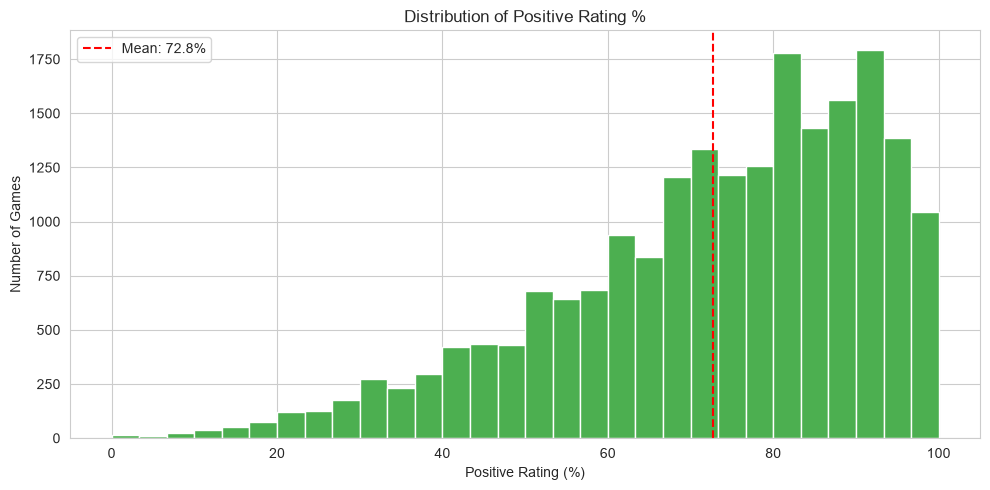

Average positive rating: 72.8%
Median positive rating:  76.6%


In [16]:
# Filter games with at least 10 ratings for meaningful analysis
df_rated = df[df['total_ratings'] >= 10].copy()
print(f"Games with 10+ ratings: {len(df_rated):,} out of {len(df):,}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_rated['positive_pct'], bins=30, color='#4CAF50', edgecolor='white')
ax.set_title('Distribution of Positive Rating %')
ax.set_xlabel('Positive Rating (%)')
ax.set_ylabel('Number of Games')
ax.axvline(df_rated['positive_pct'].mean(), color='red', linestyle='--',
           label=f"Mean: {df_rated['positive_pct'].mean():.1f}%")
ax.legend()
plt.tight_layout()
plt.savefig('07_ratings_dist.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Average positive rating: {df_rated['positive_pct'].mean():.1f}%")
print(f"Median positive rating:  {df_rated['positive_pct'].median():.1f}%")

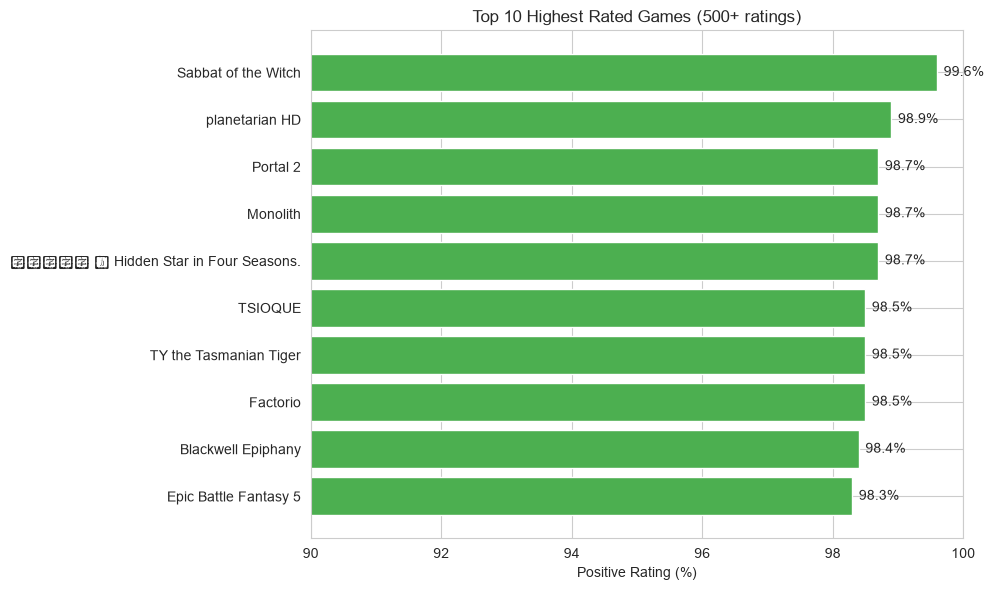

In [17]:
# Top 10 highest rated games (with at least 500 ratings)
well_rated = df[df['total_ratings'] >= 500].copy()
top_rated = well_rated.nlargest(10, 'positive_pct')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(top_rated)), top_rated['positive_pct'],
        color='#4CAF50', edgecolor='white')
ax.set_yticks(range(len(top_rated)))
ax.set_yticklabels(top_rated['name'])
ax.invert_yaxis()
ax.set_title('Top 10 Highest Rated Games (500+ ratings)')
ax.set_xlabel('Positive Rating (%)')
ax.set_xlim(90, 100)

for i, v in enumerate(top_rated['positive_pct']):
    ax.text(v + 0.1, i, f'{v:.1f}%', va='center')

plt.tight_layout()
plt.savefig('08_top_rated.png', dpi=150, bbox_inches='tight')
plt.show()

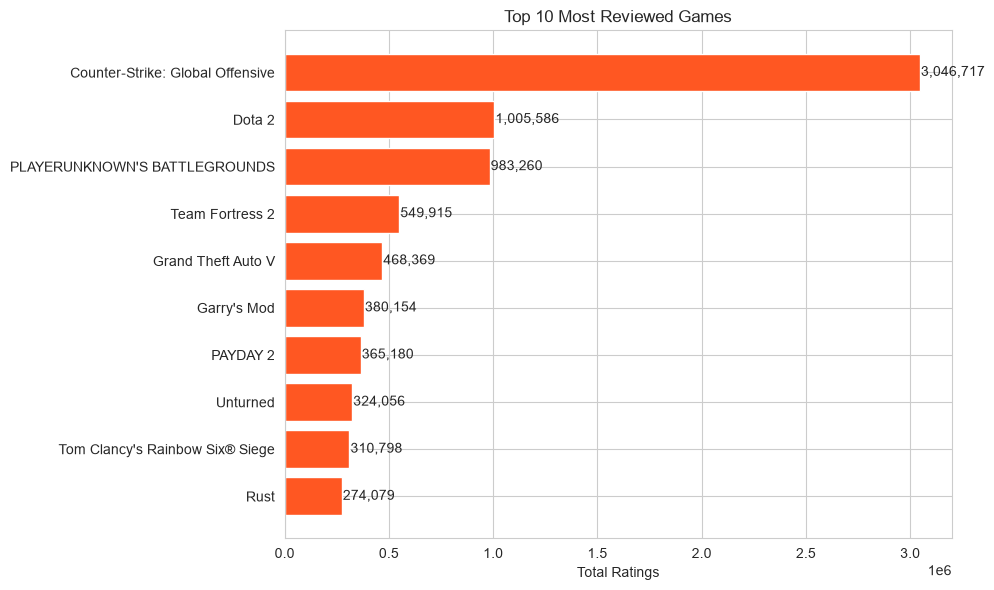

In [18]:
# Top 10 most reviewed games
top_reviewed = df.nlargest(10, 'total_ratings')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(top_reviewed)), top_reviewed['total_ratings'],
        color='#FF5722', edgecolor='white')
ax.set_yticks(range(len(top_reviewed)))
ax.set_yticklabels(top_reviewed['name'])
ax.invert_yaxis()
ax.set_title('Top 10 Most Reviewed Games')
ax.set_xlabel('Total Ratings')

for i, v in enumerate(top_reviewed['total_ratings']):
    ax.text(v + 5000, i, f'{v:,}', va='center')

plt.tight_layout()
plt.savefig('09_most_reviewed.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Release Year Trends

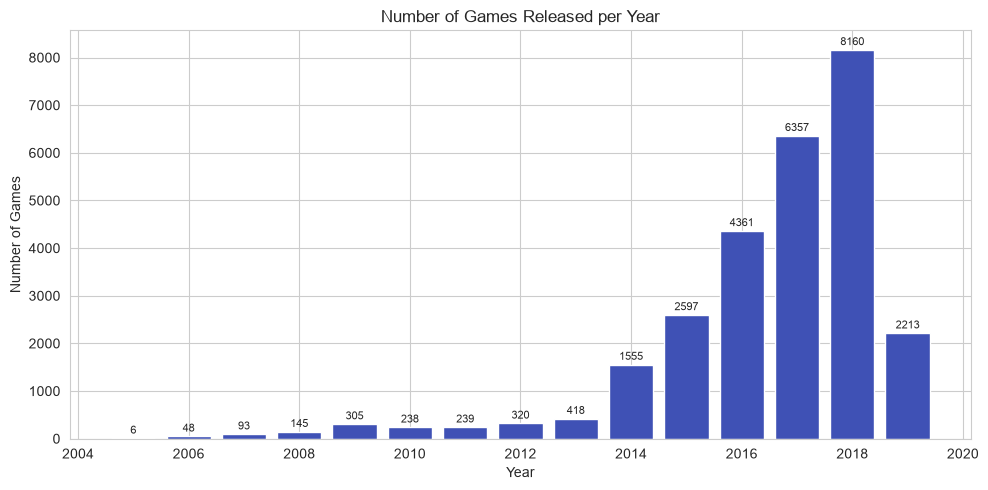

Most releases in: 2018 (8,160 games)


In [19]:
# Number of games released per year (2005-2019)
df_year = df[(df['release_year'] >= 2005) & (df['release_year'] <= 2019)]
games_per_year = df_year.groupby('release_year').size()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(games_per_year.index.astype(int), games_per_year.values,
       color='#3F51B5', edgecolor='white')
ax.set_title('Number of Games Released per Year')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Games')

# Label bars with values
for x, y in zip(games_per_year.index, games_per_year.values):
    ax.text(x, y + 100, str(y), ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('10_releases_per_year.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Most releases in: {int(games_per_year.idxmax())} ({games_per_year.max():,} games)")

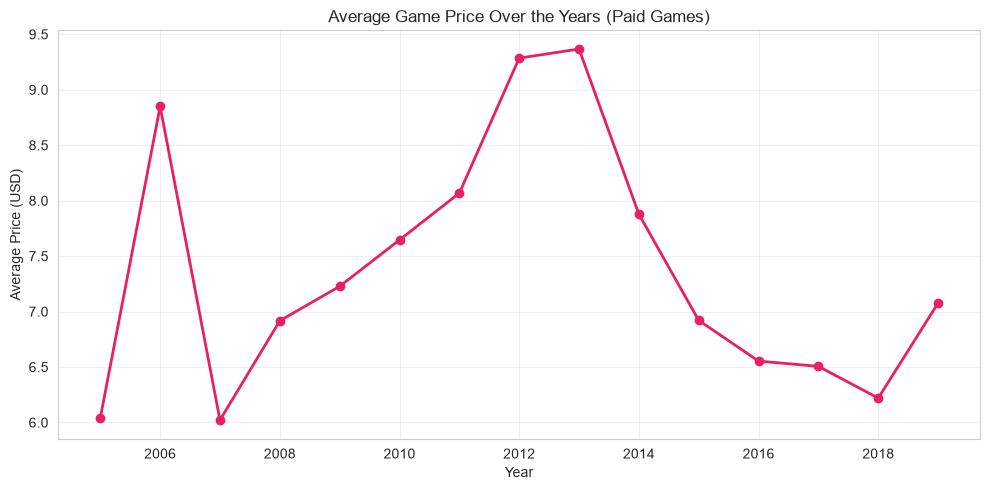

In [20]:
# Average price trend over years (paid games only)
df_year_paid = df_year[df_year['price'] > 0]
price_trend = df_year_paid.groupby('release_year')['price'].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(price_trend.index.astype(int), price_trend.values,
        marker='o', color='#E91E63', linewidth=2)
ax.set_title('Average Game Price Over the Years (Paid Games)')
ax.set_xlabel('Year')
ax.set_ylabel('Average Price (USD)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('11_price_trend.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Ownership Analysis

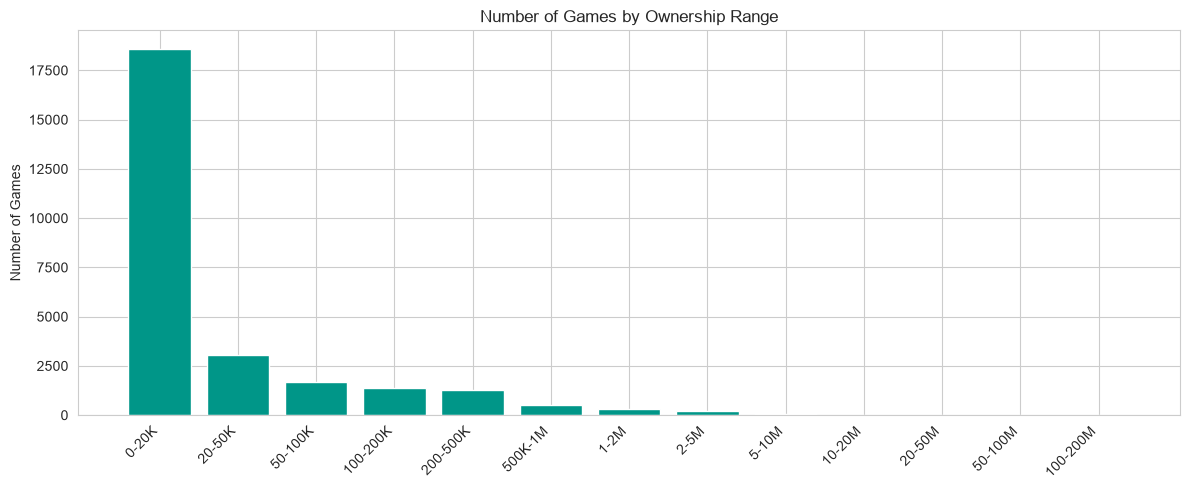

Most games fall in the 0-20K owners range
Games with 0-20K owners: 18,596


In [21]:
# Games by ownership range
owner_counts = df['owners'].value_counts()

# Sort by ownership range logically
owner_order = [
    '0-20000', '20000-50000', '50000-100000', '100000-200000',
    '200000-500000', '500000-1000000', '1000000-2000000',
    '2000000-5000000', '5000000-10000000', '10000000-20000000',
    '20000000-50000000', '50000000-100000000', '100000000-200000000'
]
owner_sorted = owner_counts.reindex(owner_order).dropna()

# Short labels for readability
short_labels = ['0-20K', '20-50K', '50-100K', '100-200K',
                '200-500K', '500K-1M', '1-2M', '2-5M',
                '5-10M', '10-20M', '20-50M', '50-100M', '100-200M']
short_labels = short_labels[:len(owner_sorted)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(owner_sorted)), owner_sorted.values,
       color='#009688', edgecolor='white')
ax.set_xticks(range(len(owner_sorted)))
ax.set_xticklabels(short_labels, rotation=45, ha='right')
ax.set_title('Number of Games by Ownership Range')
ax.set_ylabel('Number of Games')
plt.tight_layout()
plt.savefig('12_ownership.png', dpi=150, bbox_inches='tight')
plt.show()

print("Most games fall in the 0-20K owners range")
print(f"Games with 0-20K owners: {owner_sorted.iloc[0]:,}")

## 11. Top Developers & Publishers

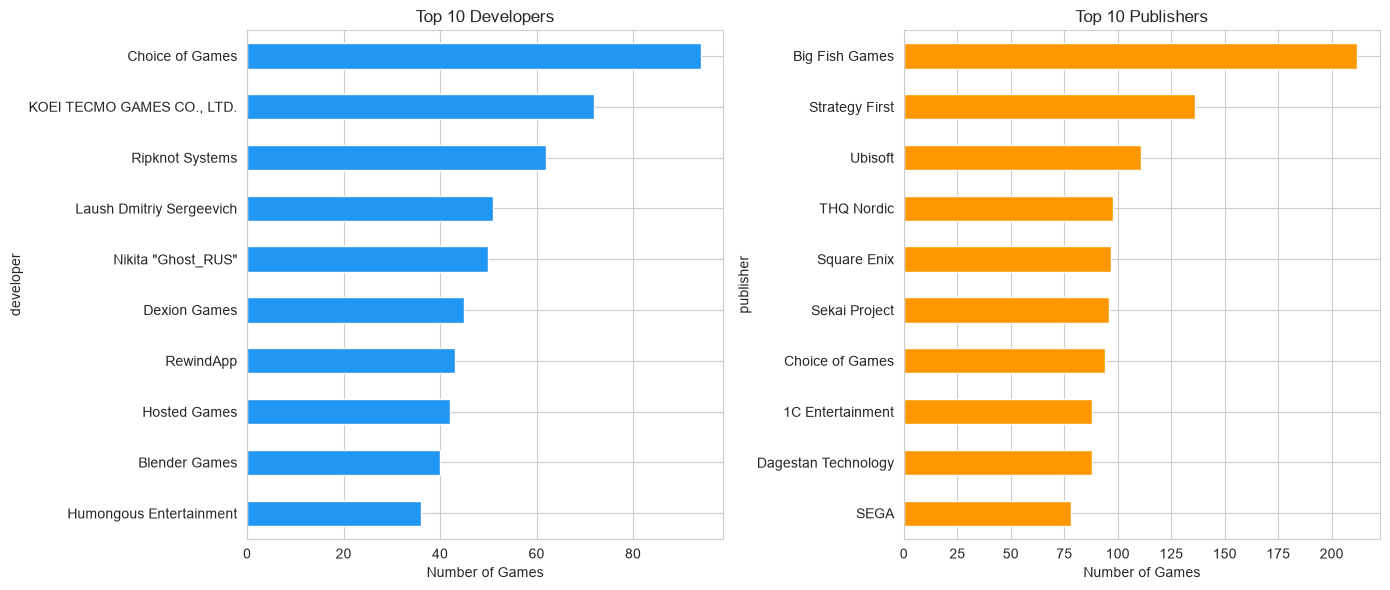

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Top 10 developers
top_devs = df['developer'].value_counts().head(10)
top_devs.plot(kind='barh', ax=axes[0], color='#2196F3', edgecolor='white')
axes[0].set_title('Top 10 Developers')
axes[0].set_xlabel('Number of Games')
axes[0].invert_yaxis()

# Top 10 publishers
top_pubs = df['publisher'].value_counts().head(10)
top_pubs.plot(kind='barh', ax=axes[1], color='#FF9800', edgecolor='white')
axes[1].set_title('Top 10 Publishers')
axes[1].set_xlabel('Number of Games')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('13_devs_publishers.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Playtime Analysis

Games with playtime > 0: 6,170 (22.8%)
Games with 0 playtime:   20,905


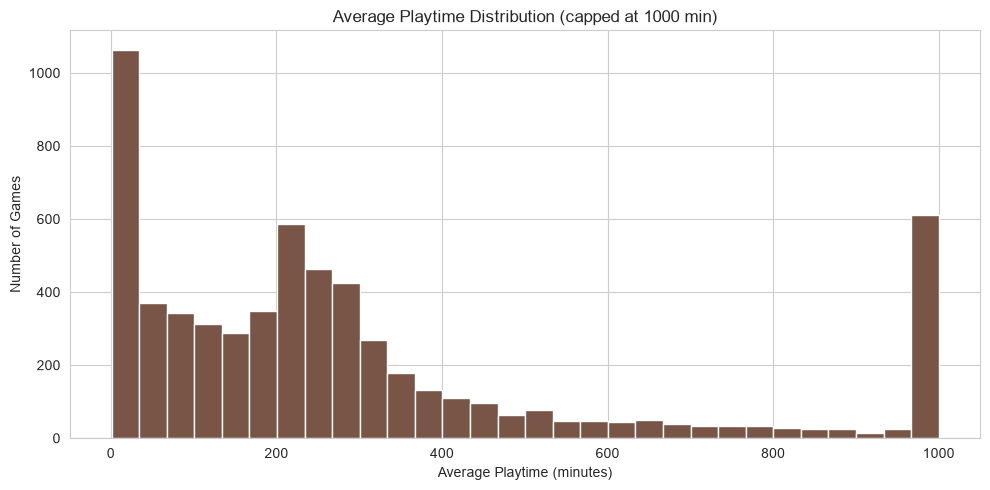

Average playtime: 11.0 hours
Median playtime:  3.7 hours


In [23]:
# How many games have playtime data?
has_playtime = df[df['average_playtime'] > 0]
print(f"Games with playtime > 0: {len(has_playtime):,} ({len(has_playtime)/len(df)*100:.1f}%)")
print(f"Games with 0 playtime:   {(df['average_playtime']==0).sum():,}")

# Average playtime distribution (cap at 1000 min for readability)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(has_playtime['average_playtime'].clip(upper=1000),
        bins=30, color='#795548', edgecolor='white')
ax.set_title('Average Playtime Distribution (capped at 1000 min)')
ax.set_xlabel('Average Playtime (minutes)')
ax.set_ylabel('Number of Games')
plt.tight_layout()
plt.savefig('14_playtime.png', dpi=150, bbox_inches='tight')
plt.show()

avg_hrs = has_playtime['average_playtime'].mean() / 60
med_hrs = has_playtime['average_playtime'].median() / 60
print(f"Average playtime: {avg_hrs:.1f} hours")
print(f"Median playtime:  {med_hrs:.1f} hours")

## 13. English vs Non-English Games

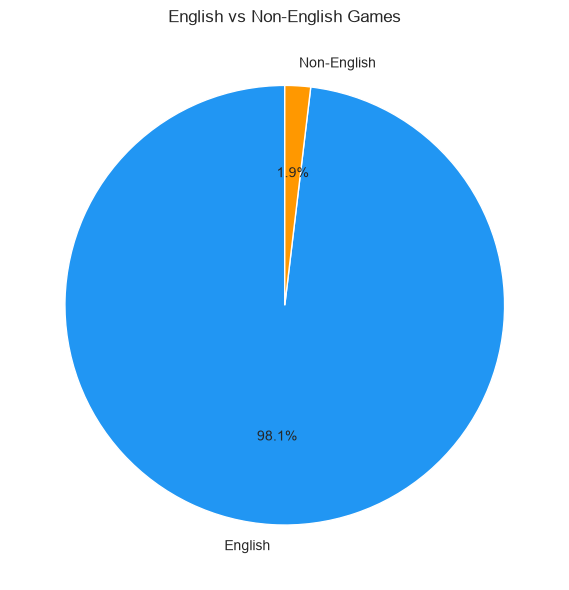

English: 26,564
Non-English: 511


In [24]:
# How many games support English?
eng_count = (df['english'] == 1).sum()
non_eng_count = (df['english'] == 0).sum()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie([eng_count, non_eng_count],
       labels=['English', 'Non-English'],
       autopct='%1.1f%%',
       colors=['#2196F3', '#FF9800'],
       startangle=90)
ax.set_title('English vs Non-English Games')
plt.tight_layout()
plt.savefig('15_english.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"English: {eng_count:,}")
print(f"Non-English: {non_eng_count:,}")

## 14. Popular SteamSpy Tags

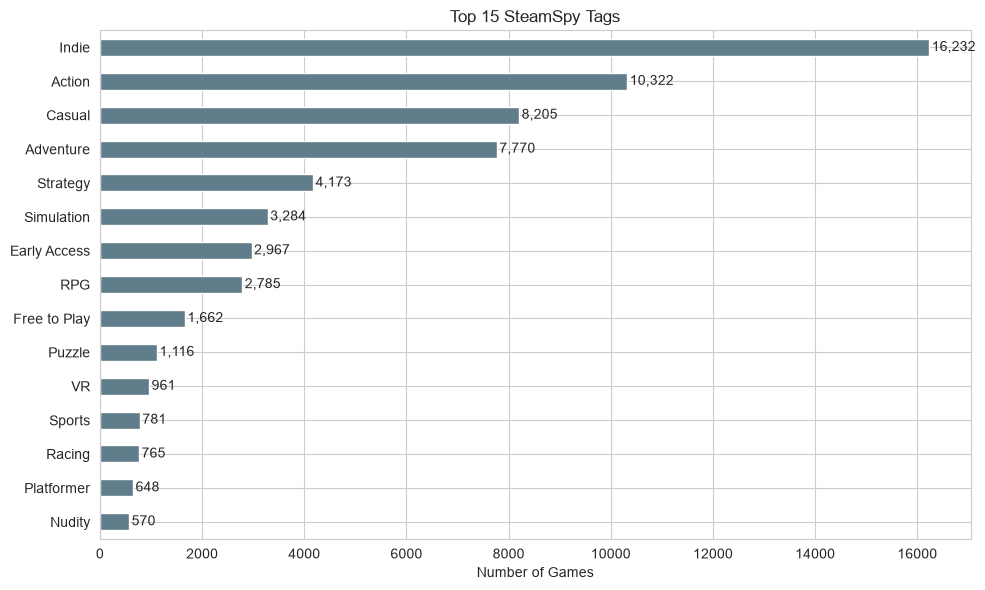

In [25]:
# Split tags and count top 15
all_tags = df['steamspy_tags'].str.split(';').explode().str.strip()
tag_counts = all_tags.value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
tag_counts.plot(kind='barh', ax=ax, color='#607D8B', edgecolor='white')
ax.set_title('Top 15 SteamSpy Tags')
ax.set_xlabel('Number of Games')
ax.set_ylabel('')
ax.invert_yaxis()

for i, v in enumerate(tag_counts.values):
    ax.text(v + 50, i, f'{v:,}', va='center')

plt.tight_layout()
plt.savefig('16_tags.png', dpi=150, bbox_inches='tight')
plt.show()

## 15. Achievements

Games WITH achievements: 15,211 (56.2%)
Games WITHOUT achievements: 11,864 (43.8%)


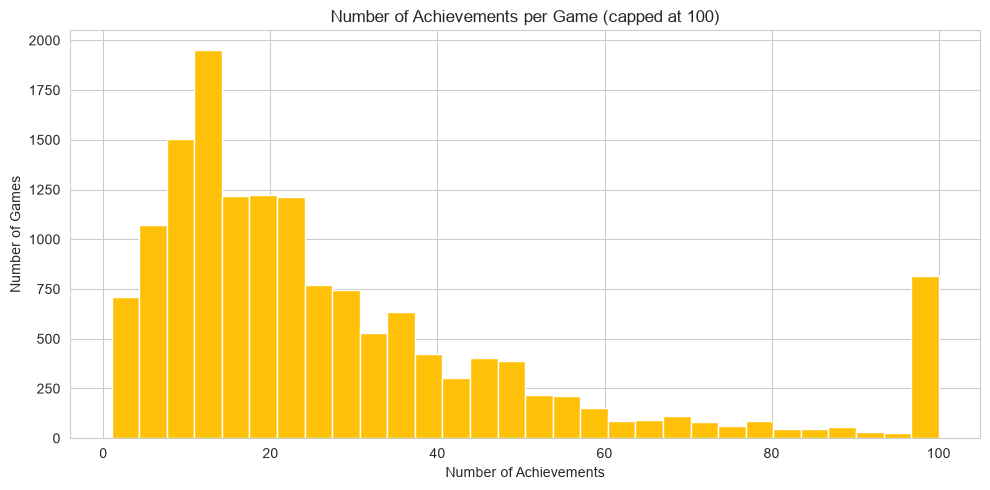

Average achievements (for games that have them): 81
Max achievements: 9821


In [26]:
# How many games have achievements?
has_achieve = (df['achievements'] > 0).sum()
no_achieve = (df['achievements'] == 0).sum()

print(f"Games WITH achievements: {has_achieve:,} ({has_achieve/len(df)*100:.1f}%)")
print(f"Games WITHOUT achievements: {no_achieve:,} ({no_achieve/len(df)*100:.1f}%)")

# Distribution for games that have achievements
df_ach = df[df['achievements'] > 0]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_ach['achievements'].clip(upper=100), bins=30,
        color='#FFC107', edgecolor='white')
ax.set_title('Number of Achievements per Game (capped at 100)')
ax.set_xlabel('Number of Achievements')
ax.set_ylabel('Number of Games')
plt.tight_layout()
plt.savefig('17_achievements.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Average achievements (for games that have them): {df_ach['achievements'].mean():.0f}")
print(f"Max achievements: {df_ach['achievements'].max()}")

## 16. Simple Correlation Check

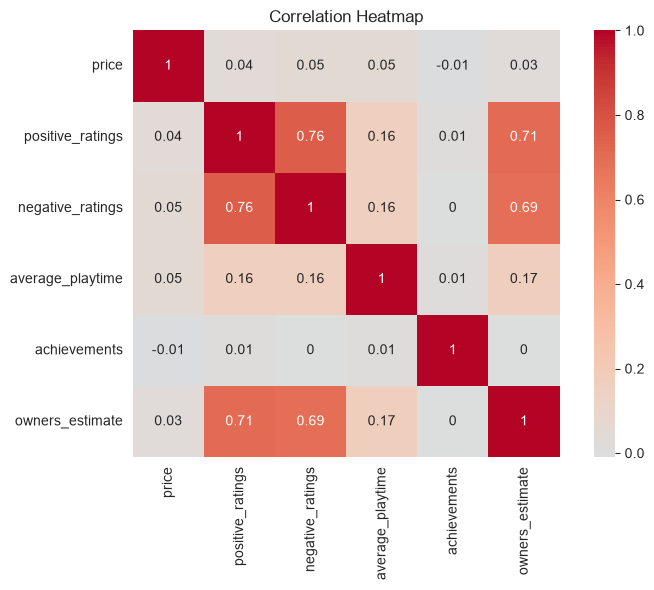

In [27]:
# Check correlations between key numeric columns
cols = ['price', 'positive_ratings', 'negative_ratings',
        'average_playtime', 'achievements', 'owners_estimate']

corr = df[cols].corr().round(2)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0,
            square=True, ax=ax)
ax.set_title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('18_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

## 17. Summary

**Key Findings:**

1. **Dataset Size:** 27,075 games in total.

2. **Pricing:** Most games are cheap — the median price is around \$4. A large number of games are free-to-play.

3. **Genres:** Indie, Action, and Casual are the most popular genres on Steam.

4. **Platforms:** Almost all games support Windows (~98%). Mac and Linux support is much lower.

5. **Ratings:** Most games have positive ratings, with an average around 75-80% positive.

6. **Growth:** The number of games released on Steam has been growing rapidly, especially after 2014.

7. **Ownership:** The majority of games have fewer than 20,000 owners, meaning most games have small audiences.

8. **Correlation:** Positive and negative ratings are correlated — popular games get more reviews overall.

---
*End of analysis.*